# Transcript Analysis Helper

Interactively explore the transcript `.txt` files housed under `data/` using the helpers defined in `script.py`.


In [48]:
from pathlib import Path

import pandas as pd

from dataloader import TranscriptLoader
# Random seed for reproducibility
RANDOM_SEED = 42

loader = TranscriptLoader()
print(f"Data directory: {loader.data_dir}")

from file_validator import validate_file_naming, print_validation_report

# Check for files that don't follow naming convention
naming_issues = validate_file_naming(Path(loader.data_dir))
print_validation_report(naming_issues)

transcript_paths = loader.discover_transcript_files()
len(transcript_paths), transcript_paths[:5]

example_path = transcript_paths[0]
example_df = loader.load_transcript(example_path)
example_df.head()



Data directory: /Users/bentindal/Desktop/CognoSpeak/data
FILE NAMING CONVENTION CHECK

Accepted formats:
  - Process-XXX__PFT.txt or Process-XXX__SFT.txt (double underscore)
  - Process-XXX_PFT.txt or Process-XXX_SFT.txt (single underscore)
Files should be in directories: Process-rec-XXX/ or Process-test-XXX/

✅ All files follow the naming convention!


,start_time,end_time,token,recording,task,recording_number,source_path
0,0.284,0.708,plank,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
1,1.948,2.532,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
2,4.09,5.0,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
3,8.092,8.9,plepthora,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
4,9.82,10.532,puzzle,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...


In [49]:
frames = loader.load_all_transcripts(transcript_paths)
combined = loader.concatenate_transcripts(frames.values())
summary = loader.summarize_structure(combined)
summary.to_frame(name='value')


,value
rows,3503
recordings,90
tasks,"PFT, SFT, UNKNOWN"
start_time_range,"(0.0, 62.262074)"
end_time_range,"(0.255492, 63.006197)"
missing_values,0


In [50]:
metadata = loader.load_metadata()
metadata.head()


,recording,age,gender,diagnosis,MMSE,annotator,notes,recording_number
0,Process-rec-143,70.0,male,DEMENTIA,24.0,Madhu,"SFT: all good, something said at the end, can'...",143
1,Process-rec-091,73.0,female,DEMENTIA,20.0,Kevin,"SFT: good, repeated a couple words towards the...",91
2,Process-test-038,73.0,male,DEMENTIA,<NA>,Kevin,"SFT: good until end, noticeable pauses; PFT: n...",38
3,Process-rec-107,75.0,female,DEMENTIA,<NA>,Kevin,"SFT: good, noticeable pauses, repeated word; P...",107
4,Process-rec-040,77.0,male,DEMENTIA,<NA>,Kevin,"SFT: all good; PFT: poor, apologised for strug...",40


In [51]:
merged = loader.merge_with_metadata(combined, metadata)
merged[['recording', 'diagnosis']].drop_duplicates().head()

output_path = Path('combined_transcripts.parquet')
combined.to_parquet(output_path, index=False)

from pathlib import Path
from pause_analyzer import analyze_pauses

pause_summary_path = Path('pause_summary.csv')
print("Generating pause_summary.csv...")
analyze_pauses(Path(loader.data_dir), pause_summary_path)
print(f"✓ Created {pause_summary_path}")




Generating pause_summary.csv...
✓ Created pause_summary.csv


## Pause Metrics by Diagnosis

Merge the pause statistics from `pause_summary.csv` with the subject metadata to compare cohorts (Dementia, MCI, HC).


In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

pause_summary = pd.read_csv('pause_summary.csv')
pause_summary['recording'] = pause_summary['transcript'].str.split('/').str[0]

pause_with_diag = pause_summary.merge(
    metadata.rename(columns={'anyon_IDs': 'recording'})[['recording', 'diagnosis']],
    on='recording',
    how='left'
)
pause_with_diag.dropna(subset=['diagnosis'], inplace=True)
pause_with_diag.head()


,transcript,token_count,pause_count,pause_mean,pause_median,pause_min,pause_max,pause_std,pause_total,pause_q1,pause_q2,pause_q3,recording,diagnosis
0,Process-rec-004/Process-rec-004__PFT.txt,24,23,1.862522,1.496000,0.472000,6.904000,1.623322,42.838000,0.664000,1.496000,2.058000,Process-rec-004,MCI
1,Process-rec-004/Process-rec-004__SFT.txt,16,15,2.456533,1.272000,0.000000,12.664000,3.273974,36.848000,0.632000,1.272000,3.512000,Process-rec-004,MCI
2,Process-rec-006/Process-rec-006_PFT.txt,18,17,2.535626,1.223342,0.190297,13.555324,3.487955,43.105637,0.581923,1.223342,2.779910,Process-rec-006,DEMENTIA
3,Process-rec-006/Process-rec-006_SFT.txt,10,9,2.439959,1.364377,0.278641,8.438261,2.835415,21.959633,0.387204,1.364377,4.278873,Process-rec-006,DEMENTIA
4,Process-rec-009/Process-rec-009__PFT.txt,26,25,1.384587,1.034487,0.188424,5.889187,1.277464,34.614670,0.500618,1.034487,1.814047,Process-rec-009,HC


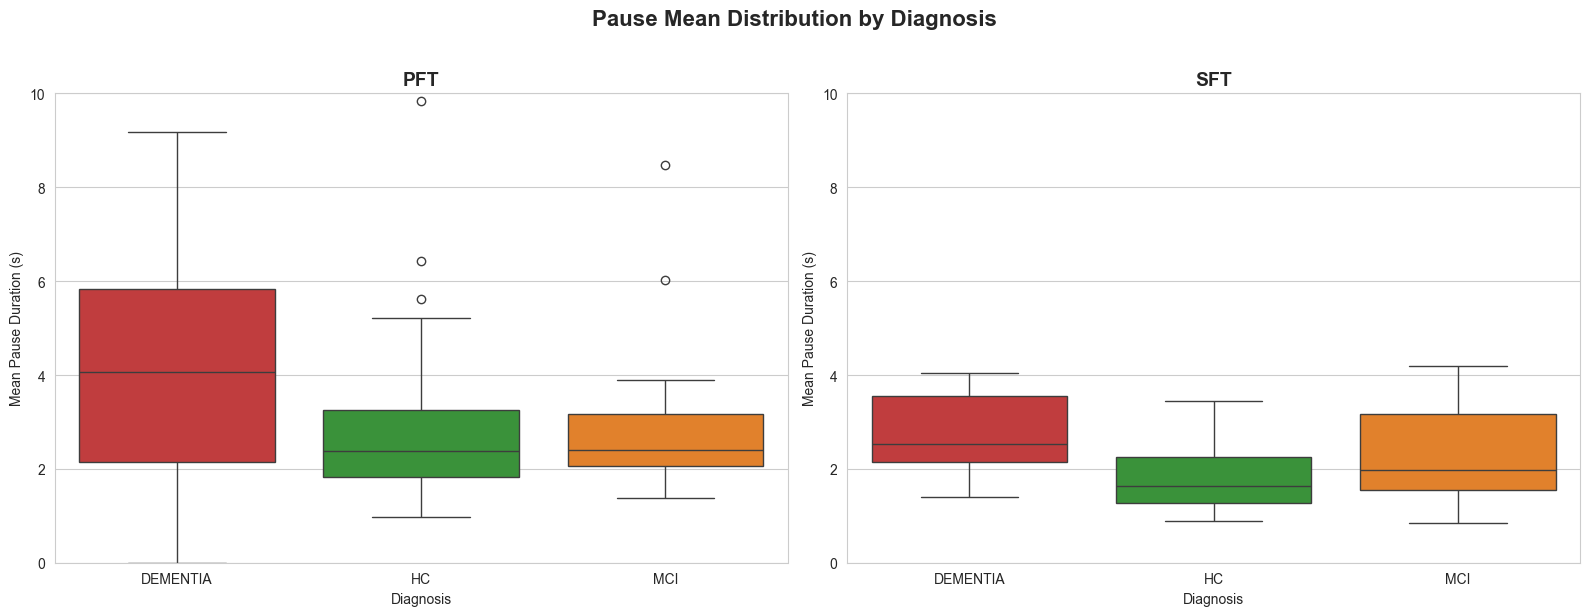


diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    22.0  4.338898  2.615377  2.152251  4.073312  5.822858
HC          40.0  2.863290  1.678258  1.834871  2.370245  3.256935
MCI         33.0  3.934765  6.896405  2.060845  2.399909  3.161694

diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    23.0  2.784005  0.847177  2.149098  2.524042  3.545156
HC          40.0  1.754666  0.637976  1.274573  1.640431  2.248435
MCI         33.0  2.179341  0.987009  1.548553  1.978552  3.171985


In [53]:
import re
from plotting import plot_3class_comparison, print_descriptive_stats

# Convert diagnosis to categorical with desired order
pause_with_diag['diagnosis'] = pd.Categorical(
    pause_with_diag['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

# Extract task (PFT/SFT) from transcript path
pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_3class_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'diagnosis')
print_descriptive_stats(sft_data, 'diagnosis')


## Statistical Tests: 3-Class Comparison

Two-tailed independent samples t-tests to compare means between diagnosis groups.


TWO-TAILED T-TESTS: PFT

DEMENTIA vs HC:
  t-statistic: 2.7047
  p-value: 0.0089
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 0.2619
  p-value: 0.7944
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 0.9504
  p-value: 0.3451
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

DEMENTIA vs HC:
  t-statistic: 5.4597
  p-value: 0.0000
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 2.3870
  p-value: 0.0205
  Significant (p < 0.05): Yes *

MCI vs HC:
  t-statistic: 2.2184
  p-value: 0.0297
  Significant (p < 0.05): Yes *


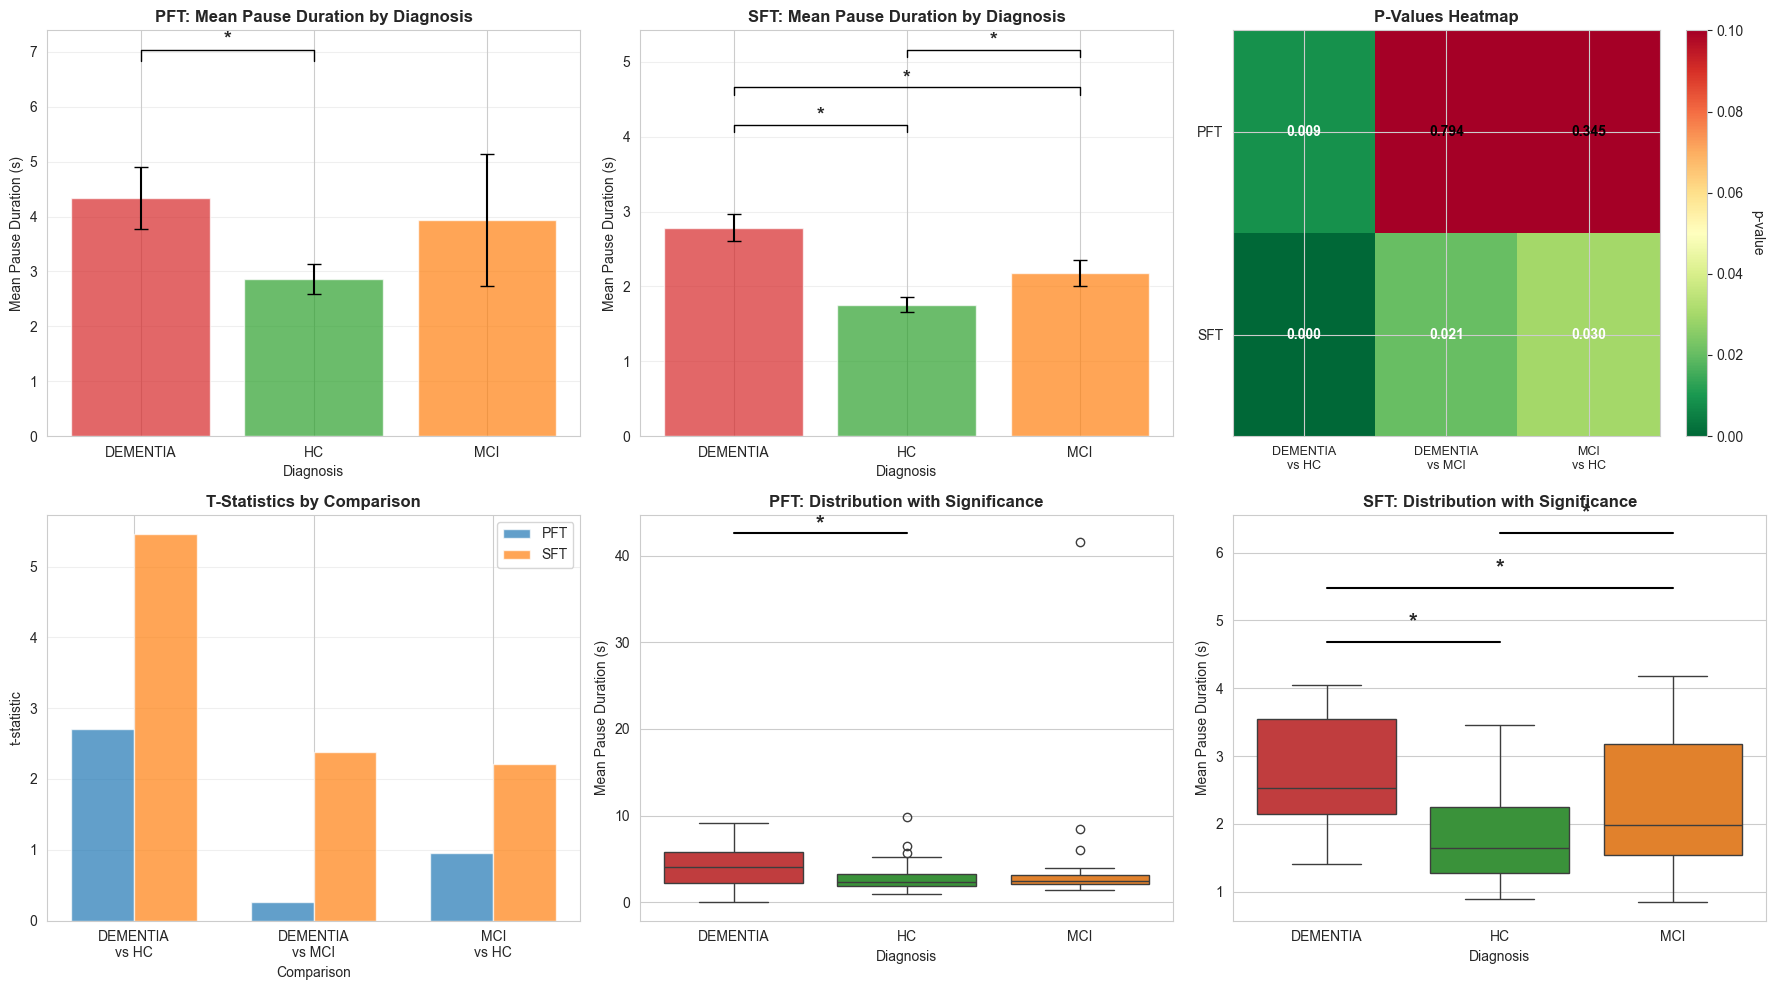


SUMMARY: Significant differences (p < 0.05) are marked with *


In [54]:
from statistical_tests import perform_3class_ttests, print_ttest_results, plot_3class_statistics

# Perform t-tests
test_results = perform_3class_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_3class_statistics(pft_data, sft_data, test_results)


## Healthy vs Non-Healthy by Task (PFT and SFT)

Compare Healthy vs Non-Healthy groups separately for PFT and SFT tasks.


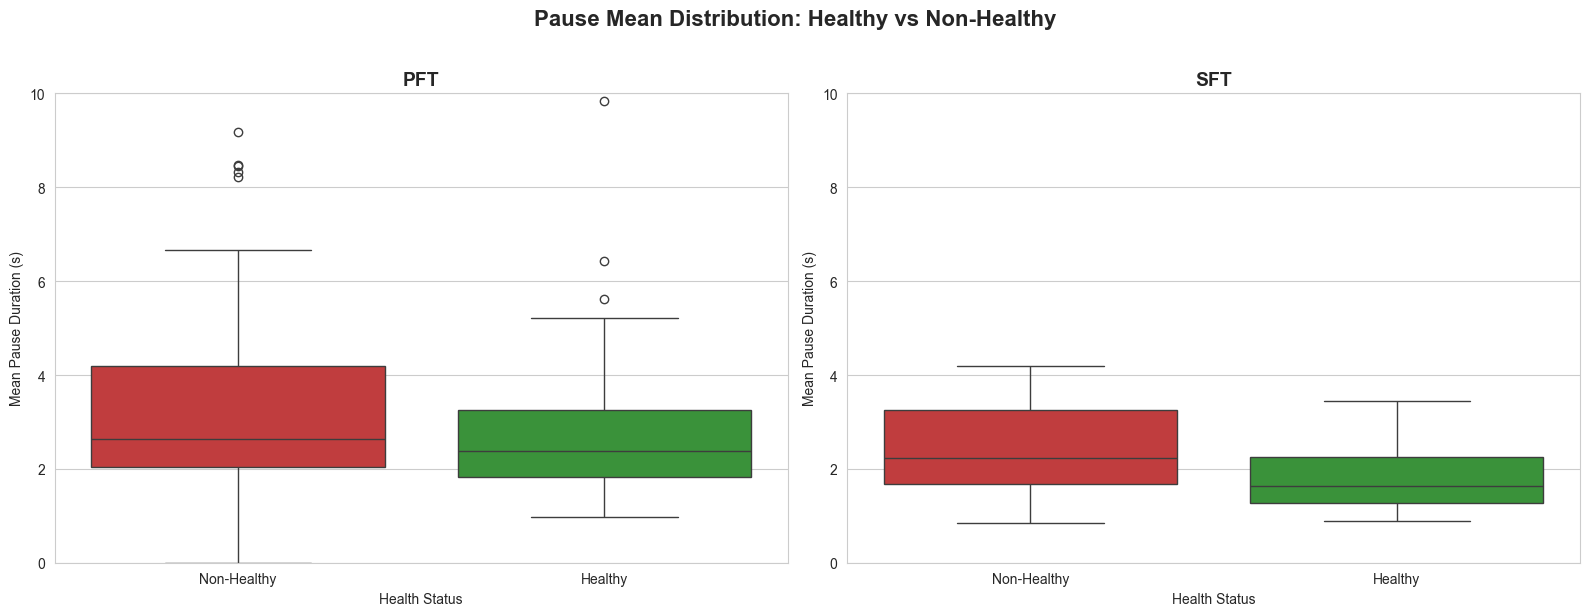


health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     55.0  4.096418  5.557332  2.042652  2.639535  4.200077
Healthy         40.0  2.863290  1.678258  1.834871  2.370245  3.256935

health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     56.0  2.427685  0.971587  1.685747  2.235373  3.252145
Healthy         40.0  1.754666  0.637976  1.274573  1.640431  2.248435


In [55]:
import re
from plotting import plot_binary_comparison, print_descriptive_stats

# Extract task (PFT/SFT) from transcript path (if not already done)
if 'task' not in pause_with_diag.columns:
    pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Create health_status if not already created
if 'health_status' not in pause_with_diag_filtered.columns:
    pause_with_diag_filtered['health_status'] = pause_with_diag_filtered['diagnosis'].apply(
        lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
    )
    pause_with_diag_filtered['health_status'] = pd.Categorical(
        pause_with_diag_filtered['health_status'],
        categories=['Non-Healthy', 'Healthy'],
        ordered=True
    )

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_binary_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'health_status')
print_descriptive_stats(sft_data, 'health_status')


## Statistical Tests: Binary Comparison (Healthy vs Non-Healthy)

Two-tailed independent samples t-tests to compare means between Healthy and Non-Healthy groups.


In [56]:
from statistical_tests import perform_binary_ttests, print_ttest_results, plot_binary_statistics

# Perform t-tests
test_results = perform_binary_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
# plot_binary_statistics(pft_data, sft_data, test_results)


TWO-TAILED T-TESTS: PFT

Healthy vs Non-Healthy:
  t-statistic: -1.3573
  p-value: 0.1780
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

Healthy vs Non-Healthy:
  t-statistic: -3.8281
  p-value: 0.0002
  Significant (p < 0.05): Yes *


## Binary Classifier: Dementia vs Healthy

Build a binary classifier using SFT pause metrics to distinguish Dementia (1) from Healthy (0). We'll use 5-fold cross-validation and visualize the results with a confusion matrix.


In [57]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

from binary_classifier import build_feature_dataset, get_classifier

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 8)


In [58]:
# Build feature dataset using SFT pause metrics only
features_df = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df)} recordings")
print(f"  - Dementia: {sum(features_df['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df['label'] == 0)}")

# Prepare features and labels
feature_cols = [col for col in features_df.columns if col.startswith('sft_')]
X = features_df[feature_cols].fillna(0)
y = features_df['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 60 recordings
  - Dementia: 20
  - Healthy (HC): 40

Using 10 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3


In [59]:
# SFT: Perform 5-fold cross-validation and collect predictions for confusion matrix
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true = []
all_y_pred = []
fold_accuracies = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Train and predict
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    
    # Store predictions
    all_y_true.extend(y_test.values)
    all_y_pred.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")


Running 5-fold cross-validation...

Fold 1: Accuracy = 0.7500
Fold 2: Accuracy = 0.9167
Fold 3: Accuracy = 0.6667
Fold 4: Accuracy = 0.8333
Fold 5: Accuracy = 0.7500

Mean accuracy across 5 folds: 0.7833 ± 0.0850


In [60]:
# Generate confusion matrix
cm = confusion_matrix(all_y_true, all_y_pred)

# Print classification report
print("Classification Report (aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true, all_y_pred, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.81      0.88      0.84        40
    Dementia       0.71      0.60      0.65        20

    accuracy                           0.78        60
   macro avg       0.76      0.74      0.75        60
weighted avg       0.78      0.78      0.78        60



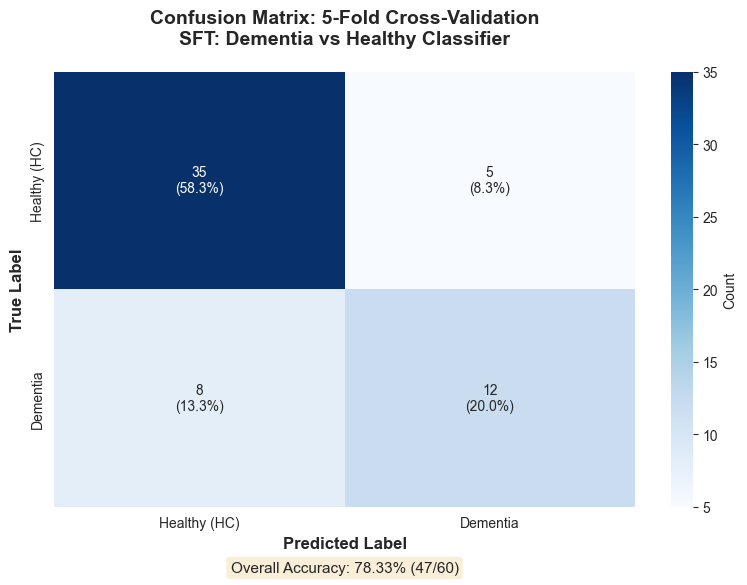

In [61]:
# Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples = cm.sum()
cm_percent_total = cm.astype('float') / total_samples * 100

# Create annotation labels with both count and percentage of total
annot_labels = []
for i in range(len(cm)):
    row = []
    for j in range(len(cm)):
        count = cm[i, j]
        percent = cm_percent_total[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nSFT: Dementia vs Healthy Classifier', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total = cm.sum()
correct = np.trace(cm)
accuracy = correct / total
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


In [62]:
from multiclass_classifier import build_feature_dataset, get_classifier, evaluate_with_cv, print_cv_results, plot_confusion_matrix

# Build feature dataset for multiclass classification (includes MCI)
features_df_multiclass = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df_multiclass)} recordings")
print("\nClass distribution:")
for label_val, count in features_df_multiclass['label'].value_counts().sort_index().items():
    diagnosis_name = features_df_multiclass[features_df_multiclass['label'] == label_val]['diagnosis'].iloc[0]
    print(f"  {diagnosis_name}: {count}")

# Prepare features and labels
feature_cols = [col for col in features_df_multiclass.columns if col.startswith('sft_')]
X_multiclass = features_df_multiclass[feature_cols].fillna(0)
y_multiclass = features_df_multiclass['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 90 recordings

Class distribution:
  HC: 40
  MCI: 30
  DEMENTIA: 20

Using 10 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3


In [63]:
# Perform 5-fold cross-validation for multiclass classification
k_folds = 5
classifier_multiclass = get_classifier('random_forest')  # Random Forest works well for multiclass

print(f"Performing {k_folds}-fold cross-validation for multiclass classification...")
cv_results_multiclass = evaluate_with_cv(X_multiclass, y_multiclass, classifier_multiclass, k_folds=k_folds)

# Display CV results as a pandas DataFrame
cv_results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Mean': [
        cv_results_multiclass['accuracy_mean'],
        cv_results_multiclass['precision_mean'],
        cv_results_multiclass['recall_mean'],
        cv_results_multiclass['f1_mean']
    ],
    'Std': [
        cv_results_multiclass['accuracy_std'],
        cv_results_multiclass['precision_std'],
        cv_results_multiclass['recall_std'],
        cv_results_multiclass['f1_std']
    ]
})
cv_results_df['Mean ± Std'] = cv_results_df.apply(
    lambda row: f"{row['Mean']:.4f} ± {row['Std']:.4f}", axis=1
)
cv_results_df = cv_results_df[['Metric', 'Mean ± Std']]

print("\n" + "=" * 80)
print("K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)")
print("=" * 80)
display(cv_results_df)
print("=" * 80 + "\n")


Performing 5-fold cross-validation for multiclass classification...

K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)


,Metric,Mean ± Std
0,Accuracy,0.5778 ± 0.1144
1,Precision (Macro),0.5603 ± 0.1722
2,Recall (Macro),0.5583 ± 0.1225
3,F1-Score (Macro),0.5388 ± 0.1397


In [64]:
# Per-fold demographics (5-fold StratifiedKFold, random_state=RANDOM_SEED)
# Ensures we use the same splits as the multiclass CV below
from sklearn.model_selection import StratifiedKFold

df_demo = features_df_multiclass.merge(
    metadata[['recording', 'age', 'gender']],
    on='recording',
    how='left',
)
cv_demo = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

def _demog_summary(d):
    n = len(d)
    if n == 0:
        return {'n': 0, 'male': 0, 'female': 0, 'age_mean': None, 'age_std': None, 'HC': 0, 'MCI': 0, 'DEMENTIA': 0}
    g = d['gender'].value_counts()
    age = d['age'].dropna()
    diag = d['diagnosis'].value_counts()
    return {
        'n': n,
        'male': int(g.get('male', 0)),
        'female': int(g.get('female', 0)),
        'age_mean': round(age.mean(), 1) if len(age) else None,
        'age_std': round(age.std(), 1) if len(age) and age.std() is not None else None,
        'HC': int(diag.get('HC', 0)),
        'MCI': int(diag.get('MCI', 0)),
        'DEMENTIA': int(diag.get('DEMENTIA', 0)),
    }

rows = []
for fold_idx, (train_idx, test_idx) in enumerate(cv_demo.split(X_multiclass, y_multiclass), 1):
    train_df = df_demo.iloc[train_idx]
    test_df = df_demo.iloc[test_idx]
    tr = _demog_summary(train_df)
    te = _demog_summary(test_df)
    rows.append({
        'Fold': fold_idx,
        'Split': 'Train',
        'n': tr['n'],
        'Male': tr['male'],
        'Female': tr['female'],
        'Age mean±std': f"{tr['age_mean']} ± {tr['age_std']}" if tr['age_mean'] is not None else '—',
        'HC': tr['HC'],
        'MCI': tr['MCI'],
        'DEMENTIA': tr['DEMENTIA'],
    })
    rows.append({
        'Fold': fold_idx,
        'Split': 'Test',
        'n': te['n'],
        'Male': te['male'],
        'Female': te['female'],
        'Age mean±std': f"{te['age_mean']} ± {te['age_std']}" if te['age_mean'] is not None else '—',
        'HC': te['HC'],
        'MCI': te['MCI'],
        'DEMENTIA': te['DEMENTIA'],
    })

demo_df = pd.DataFrame(rows)
print("Per-fold demographics (multiclass 5-fold CV, seed=42)\n")
display(demo_df)

Per-fold demographics (multiclass 5-fold CV, seed=42)



,Fold,Split,n,Male,Female,Age mean±std,HC,MCI,DEMENTIA
0,1,Train,72,41,31,72.5 ± 5.7,32,24,16
1,1,Test,18,8,10,73.2 ± 4.9,8,6,4
2,2,Train,72,42,30,72.7 ± 5.5,32,24,16
3,2,Test,18,7,11,72.7 ± 5.7,8,6,4
4,3,Train,72,36,36,72.5 ± 5.5,32,24,16
5,3,Test,18,13,5,73.2 ± 5.8,8,6,4
6,4,Train,72,38,34,72.8 ± 5.0,32,24,16
7,4,Test,18,11,7,72.3 ± 7.4,8,6,4
8,5,Train,72,39,33,72.8 ± 5.9,32,24,16
9,5,Test,18,10,8,72.0 ± 3.6,8,6,4


In [65]:
# Collect predictions across all folds for confusion matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
all_y_true_multiclass = []
all_y_pred_multiclass = []

print(f"Running {k_folds}-fold cross-validation to collect predictions...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_multiclass, y_multiclass), 1):
    X_train, X_test = X_multiclass.iloc[train_idx], X_multiclass.iloc[test_idx]
    y_train, y_test = y_multiclass.iloc[train_idx], y_multiclass.iloc[test_idx]
    
    # Train and predict
    classifier_multiclass.fit(X_train, y_train)
    y_pred = classifier_multiclass.predict(X_test)
    
    # Store predictions
    all_y_true_multiclass.extend(y_test.values)
    all_y_pred_multiclass.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean([(np.array(all_y_pred_multiclass)[i::k_folds] == np.array(all_y_true_multiclass)[i::k_folds]).mean() for i in range(k_folds)]):.4f}")


Running 5-fold cross-validation to collect predictions...

Fold 1: Accuracy = 0.6667
Fold 2: Accuracy = 0.4444
Fold 3: Accuracy = 0.4444
Fold 4: Accuracy = 0.6111
Fold 5: Accuracy = 0.7222

Mean accuracy across 5 folds: 0.5778


In [66]:
# Create detailed classification report as pandas DataFrame

# Calculate per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    all_y_true_multiclass,
    all_y_pred_multiclass,
    labels=[0, 1, 2],
    zero_division=0
)

# Create DataFrame
class_names = ['HC', 'MCI', 'Dementia']
classification_results_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

# Format for display
classification_results_df['Precision'] = classification_results_df['Precision'].apply(lambda x: f'{x:.4f}')
classification_results_df['Recall'] = classification_results_df['Recall'].apply(lambda x: f'{x:.4f}')
classification_results_df['F1-Score'] = classification_results_df['F1-Score'].apply(lambda x: f'{x:.4f}')

print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORT (Per-Class Metrics)")
print("=" * 80)
display(classification_results_df)

# Calculate overall accuracy
overall_accuracy = accuracy_score(all_y_true_multiclass, all_y_pred_multiclass)
print(f"\nOverall Accuracy: {overall_accuracy:.4f} ({overall_accuracy*100:.2f}%)")
print(f"Total Samples: {len(all_y_true_multiclass)}")
print("=" * 80 + "\n")



DETAILED CLASSIFICATION REPORT (Per-Class Metrics)


,Class,Precision,Recall,F1-Score,Support
0,HC,0.6585,0.6750,0.6667,40
1,MCI,0.5000,0.5000,0.5000,30
2,Dementia,0.5263,0.5000,0.5128,20



Overall Accuracy: 0.5778 (57.78%)
Total Samples: 90



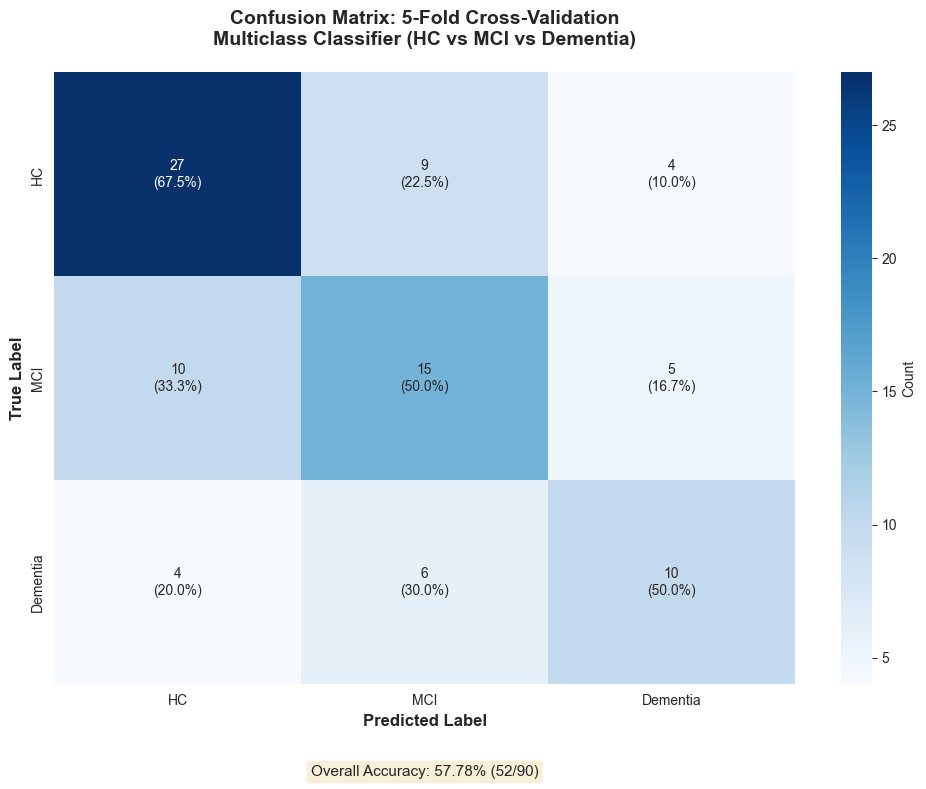

In [67]:
# Plot confusion matrix for multiclass classification
cm_multiclass = confusion_matrix(all_y_true_multiclass, all_y_pred_multiclass)

fig, ax = plt.subplots(figsize=(10, 8))

# Calculate percentages of each row (true class)
# This ensures each row sums to exactly 100%
row_sums = cm_multiclass.sum(axis=1)
# Avoid division by zero (shouldn't happen, but safety check)
row_sums = np.where(row_sums == 0, 1, row_sums)

# Calculate percentages and normalize to ensure each row sums to exactly 100%
cm_percent = np.zeros_like(cm_multiclass, dtype=float)
for i in range(len(cm_multiclass)):
    if row_sums[i] > 0:
        # Calculate percentages for this row
        cm_percent[i, :] = cm_multiclass[i, :].astype('float') / row_sums[i] * 100
        # Ensure it sums to exactly 100% by normalizing
        row_total = cm_percent[i, :].sum()
        if row_total > 0:
            cm_percent[i, :] = cm_percent[i, :] / row_total * 100

# Create annotation labels with both count and percentage
annot_labels = []
class_names = ['HC', 'MCI', 'Dementia']
for i in range(len(cm_multiclass)):
    row = []
    for j in range(len(cm_multiclass)):
        count = cm_multiclass[i, j]
        percent = cm_percent[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap
sns.heatmap(
    cm_multiclass, 
    annot=annot_labels, 
    fmt='', 
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'},
    ax=ax
)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(
    'Confusion Matrix: 5-Fold Cross-Validation\nMulticlass Classifier (HC vs MCI vs Dementia)',
    fontsize=14,
    fontweight='bold',
    pad=20
)

# Add accuracy text
total = cm_multiclass.sum()
correct = np.trace(cm_multiclass)
accuracy = correct / total
ax.text(
    0.5, -0.15,
    f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
    transform=ax.transAxes,
    ha='center',
    fontsize=11,
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
)

plt.tight_layout()
plt.show()


In [68]:
# Display confusion matrix as pandas DataFrame
cm_df = pd.DataFrame(
    cm_multiclass,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

# Add row totals
cm_df['Total'] = cm_df.sum(axis=1)

# Calculate percentages for each row
cm_percent_df = pd.DataFrame(
    cm_percent,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Counts)")
print("=" * 80)
display(cm_df)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Percentages - each row sums to 100%)")
print("=" * 80)
# Format percentages
cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')
display(cm_percent_df_formatted)
print("=" * 80 + "\n")



CONFUSION MATRIX (Counts)


,Pred: HC,Pred: MCI,Pred: Dementia,Total
True: HC,27,9,4,40
True: MCI,10,15,5,30
True: Dementia,4,6,10,20



CONFUSION MATRIX (Percentages - each row sums to 100%)


/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89084/3657399134.py:27: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')


,Pred: HC,Pred: MCI,Pred: Dementia
True: HC,67.5%,22.5%,10.0%
True: MCI,33.3%,50.0%,16.7%
True: Dementia,20.0%,30.0%,50.0%


## Binary Classifier: Healthy vs Non-Healthy (SFT)

Build a binary classifier using SFT pause metrics to distinguish Healthy (0) from Non-Healthy (MCI + Dementia = 1). We use the `non_healthy` MCI strategy to merge MCI and Dementia into a single class.

In [69]:
from mci_impact_analysis import build_feature_dataset_with_mci

features_df_binary_nh = build_feature_dataset_with_mci(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=True,
    mci_strategy='non_healthy',
)

print(f"Loaded {len(features_df_binary_nh)} recordings")
print(f"  - Healthy (HC): {sum(features_df_binary_nh['label'] == 0)}")
print(f"  - Non-Healthy (MCI + Dementia): {sum(features_df_binary_nh['label'] == 1)}")

feature_cols_sft_bin = [col for col in features_df_binary_nh.columns if col.startswith('sft_')]
X_bin_sft = features_df_binary_nh[feature_cols_sft_bin].fillna(0)
y_bin_sft = features_df_binary_nh['label']

print(f"\nUsing {len(feature_cols_sft_bin)} SFT pause features:")
for col in feature_cols_sft_bin:
    print(f"  - {col}")

Loaded 90 recordings
  - Healthy (HC): 40
  - Non-Healthy (MCI + Dementia): 50

Using 10 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3


In [70]:
from binary_classifier import get_classifier as get_binary_classifier

k_folds = 5
cv_bin_sft = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier_bin_sft = get_binary_classifier('logistic')

all_y_true_bin_sft = []
all_y_pred_bin_sft = []
fold_accuracies_bin_sft = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv_bin_sft.split(X_bin_sft, y_bin_sft), 1):
    X_train, X_test = X_bin_sft.iloc[train_idx], X_bin_sft.iloc[test_idx]
    y_train, y_test = y_bin_sft.iloc[train_idx], y_bin_sft.iloc[test_idx]

    classifier_bin_sft.fit(X_train, y_train)
    y_pred = classifier_bin_sft.predict(X_test)

    all_y_true_bin_sft.extend(y_test.values)
    all_y_pred_bin_sft.extend(y_pred)

    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies_bin_sft.append(fold_acc)

    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies_bin_sft):.4f} ± {np.std(fold_accuracies_bin_sft):.4f}")

Running 5-fold cross-validation...

Fold 1: Accuracy = 0.7222
Fold 2: Accuracy = 0.7222
Fold 3: Accuracy = 0.6667
Fold 4: Accuracy = 0.5000
Fold 5: Accuracy = 0.7778

Mean accuracy across 5 folds: 0.6778 ± 0.0956


In [71]:
cm_bin_sft = confusion_matrix(all_y_true_bin_sft, all_y_pred_bin_sft)

print("Classification Report (aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true_bin_sft, all_y_pred_bin_sft,
                          target_names=['Healthy (HC)', 'Non-Healthy']))
print("=" * 60)

Classification Report (aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.63      0.68      0.65        40
 Non-Healthy       0.72      0.68      0.70        50

    accuracy                           0.68        90
   macro avg       0.68      0.68      0.68        90
weighted avg       0.68      0.68      0.68        90



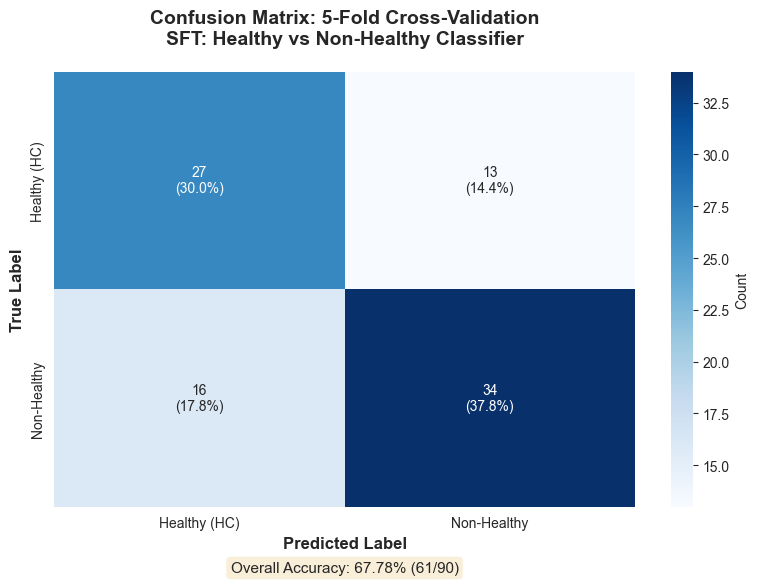

In [72]:
fig, ax = plt.subplots(figsize=(8, 6))

total_samples = cm_bin_sft.sum()
cm_percent_total = cm_bin_sft.astype('float') / total_samples * 100

annot_labels = []
for i in range(len(cm_bin_sft)):
    row = []
    for j in range(len(cm_bin_sft)):
        count = cm_bin_sft[i, j]
        percent = cm_percent_total[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

sns.heatmap(cm_bin_sft, annot=annot_labels, fmt='', cmap='Blues',
            xticklabels=['Healthy (HC)', 'Non-Healthy'],
            yticklabels=['Healthy (HC)', 'Non-Healthy'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nSFT: Healthy vs Non-Healthy Classifier',
             fontsize=14, fontweight='bold', pad=20)

total = cm_bin_sft.sum()
correct = np.trace(cm_bin_sft)
accuracy = correct / total
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

## Binary Classifier: Healthy vs Non-Healthy (PFT)

Same binary task (HC vs Non-Healthy) but using PFT pause metrics instead of SFT. Recordings with missing PFT data (all-zero features) are filtered out.

In [73]:
feature_cols_pft_bin = [col for col in features_df_binary_nh.columns if col.startswith('pft_')]

# Filter out recordings where PFT data is missing (all-zero features)
pft_mask = features_df_binary_nh[feature_cols_pft_bin].sum(axis=1) > 0
features_df_bin_pft = features_df_binary_nh[pft_mask].copy()

X_bin_pft = features_df_bin_pft[feature_cols_pft_bin].fillna(0)
y_bin_pft = features_df_bin_pft['label']

print(f"Recordings with valid PFT data: {len(features_df_bin_pft)} / {len(features_df_binary_nh)}")
print(f"  - Healthy (HC): {sum(y_bin_pft == 0)}")
print(f"  - Non-Healthy (MCI + Dementia): {sum(y_bin_pft == 1)}")

print(f"\nUsing {len(feature_cols_pft_bin)} PFT pause features:")
for col in feature_cols_pft_bin:
    print(f"  - {col}")

Recordings with valid PFT data: 89 / 90
  - Healthy (HC): 40
  - Non-Healthy (MCI + Dementia): 49

Using 10 PFT pause features:
  - pft_pause_count
  - pft_pause_mean
  - pft_pause_median
  - pft_pause_min
  - pft_pause_max
  - pft_pause_std
  - pft_pause_total
  - pft_pause_q1
  - pft_pause_q2
  - pft_pause_q3


In [74]:
k_folds = 5
cv_bin_pft = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier_bin_pft = get_binary_classifier('logistic')

all_y_true_bin_pft = []
all_y_pred_bin_pft = []
fold_accuracies_bin_pft = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv_bin_pft.split(X_bin_pft, y_bin_pft), 1):
    X_train, X_test = X_bin_pft.iloc[train_idx], X_bin_pft.iloc[test_idx]
    y_train, y_test = y_bin_pft.iloc[train_idx], y_bin_pft.iloc[test_idx]

    classifier_bin_pft.fit(X_train, y_train)
    y_pred = classifier_bin_pft.predict(X_test)

    all_y_true_bin_pft.extend(y_test.values)
    all_y_pred_bin_pft.extend(y_pred)

    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies_bin_pft.append(fold_acc)

    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies_bin_pft):.4f} ± {np.std(fold_accuracies_bin_pft):.4f}")

Running 5-fold cross-validation...

Fold 1: Accuracy = 0.6667
Fold 2: Accuracy = 0.6111
Fold 3: Accuracy = 0.6667
Fold 4: Accuracy = 0.5556
Fold 5: Accuracy = 0.6471

Mean accuracy across 5 folds: 0.6294 ± 0.0421


In [75]:
cm_bin_pft = confusion_matrix(all_y_true_bin_pft, all_y_pred_bin_pft)

print("Classification Report (aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true_bin_pft, all_y_pred_bin_pft,
                          target_names=['Healthy (HC)', 'Non-Healthy']))
print("=" * 60)

Classification Report (aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.59      0.60      0.59        40
 Non-Healthy       0.67      0.65      0.66        49

    accuracy                           0.63        89
   macro avg       0.63      0.63      0.63        89
weighted avg       0.63      0.63      0.63        89



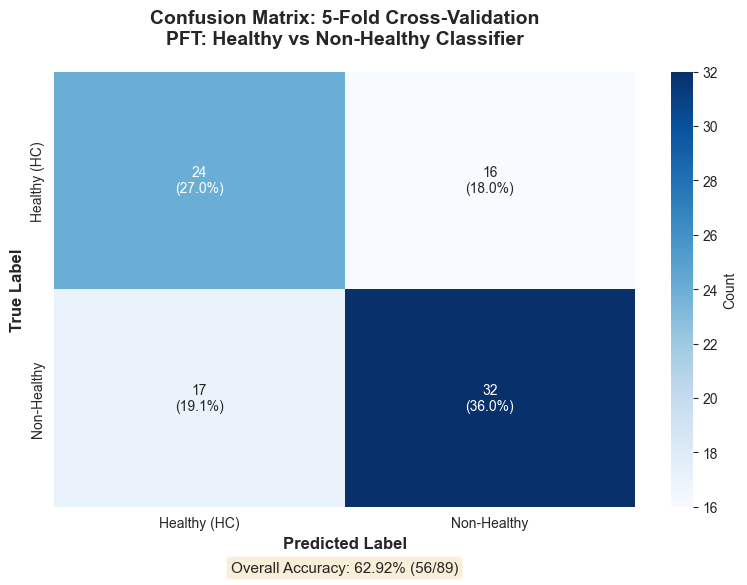

In [76]:
fig, ax = plt.subplots(figsize=(8, 6))

total_samples = cm_bin_pft.sum()
cm_percent_total = cm_bin_pft.astype('float') / total_samples * 100

annot_labels = []
for i in range(len(cm_bin_pft)):
    row = []
    for j in range(len(cm_bin_pft)):
        count = cm_bin_pft[i, j]
        percent = cm_percent_total[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

sns.heatmap(cm_bin_pft, annot=annot_labels, fmt='', cmap='Blues',
            xticklabels=['Healthy (HC)', 'Non-Healthy'],
            yticklabels=['Healthy (HC)', 'Non-Healthy'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nPFT: Healthy vs Non-Healthy Classifier',
             fontsize=14, fontweight='bold', pad=20)

total = cm_bin_pft.sum()
correct = np.trace(cm_bin_pft)
accuracy = correct / total
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

## Multiclass Classifier: HC vs MCI vs Dementia (PFT)

Three-class classification using PFT pause metrics. Recordings with missing PFT data are filtered out. Uses Random Forest with 5-fold stratified cross-validation.

In [77]:
from multiclass_classifier import build_feature_dataset as build_multiclass_dataset
from multiclass_classifier import get_classifier as get_multiclass_classifier

features_df_mc_pft = build_multiclass_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=True,
)

feature_cols_pft_mc = [col for col in features_df_mc_pft.columns if col.startswith('pft_')]

# Filter out recordings where PFT data is missing (all-zero features)
pft_mask_mc = features_df_mc_pft[feature_cols_pft_mc].sum(axis=1) > 0
features_df_mc_pft = features_df_mc_pft[pft_mask_mc].copy()

X_mc_pft = features_df_mc_pft[feature_cols_pft_mc].fillna(0)
y_mc_pft = features_df_mc_pft['label']

print(f"Recordings with valid PFT data: {pft_mask_mc.sum()} / {len(pft_mask_mc)}")
print("\nClass distribution:")
for label_val, count in y_mc_pft.value_counts().sort_index().items():
    diagnosis_name = features_df_mc_pft[features_df_mc_pft['label'] == label_val]['diagnosis'].iloc[0]
    print(f"  {diagnosis_name}: {count}")

print(f"\nUsing {len(feature_cols_pft_mc)} PFT pause features:")
for col in feature_cols_pft_mc:
    print(f"  - {col}")

Recordings with valid PFT data: 89 / 90

Class distribution:
  HC: 40
  MCI: 30
  DEMENTIA: 19

Using 10 PFT pause features:
  - pft_pause_count
  - pft_pause_mean
  - pft_pause_median
  - pft_pause_min
  - pft_pause_max
  - pft_pause_std
  - pft_pause_total
  - pft_pause_q1
  - pft_pause_q2
  - pft_pause_q3


In [78]:
k_folds = 5
cv_mc_pft = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier_mc_pft = get_multiclass_classifier('random_forest')

all_y_true_mc_pft = []
all_y_pred_mc_pft = []
fold_accuracies_mc_pft = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv_mc_pft.split(X_mc_pft, y_mc_pft), 1):
    X_train, X_test = X_mc_pft.iloc[train_idx], X_mc_pft.iloc[test_idx]
    y_train, y_test = y_mc_pft.iloc[train_idx], y_mc_pft.iloc[test_idx]

    classifier_mc_pft.fit(X_train, y_train)
    y_pred = classifier_mc_pft.predict(X_test)

    all_y_true_mc_pft.extend(y_test.values)
    all_y_pred_mc_pft.extend(y_pred)

    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies_mc_pft.append(fold_acc)

    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies_mc_pft):.4f} ± {np.std(fold_accuracies_mc_pft):.4f}")

Running 5-fold cross-validation...

Fold 1: Accuracy = 0.5556
Fold 2: Accuracy = 0.5556
Fold 3: Accuracy = 0.5556
Fold 4: Accuracy = 0.4444
Fold 5: Accuracy = 0.6471

Mean accuracy across 5 folds: 0.5516 ± 0.0643


In [79]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

cm_mc_pft = confusion_matrix(all_y_true_mc_pft, all_y_pred_mc_pft)

precision, recall, f1, support = precision_recall_fscore_support(
    all_y_true_mc_pft, all_y_pred_mc_pft, average=None
)

class_names_mc = ['HC', 'MCI', 'DEMENTIA']
report_df = pd.DataFrame({
    'Class': class_names_mc,
    'Precision': [f'{p:.4f}' for p in precision],
    'Recall': [f'{r:.4f}' for r in recall],
    'F1-Score': [f'{f:.4f}' for f in f1],
    'Support': support.astype(int),
})

print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORT (Per-Class Metrics)")
print("=" * 80)
display(report_df)

overall_accuracy = accuracy_score(all_y_true_mc_pft, all_y_pred_mc_pft)
print(f"\nOverall Accuracy: {overall_accuracy:.4f}")
print(f"Total Samples: {len(all_y_true_mc_pft)}")
print("=" * 80)


DETAILED CLASSIFICATION REPORT (Per-Class Metrics)


,Class,Precision,Recall,F1-Score,Support
0,HC,0.6000,0.6000,0.6000,40
1,MCI,0.5161,0.5333,0.5246,30
2,DEMENTIA,0.5000,0.4737,0.4865,19



Overall Accuracy: 0.5506
Total Samples: 89


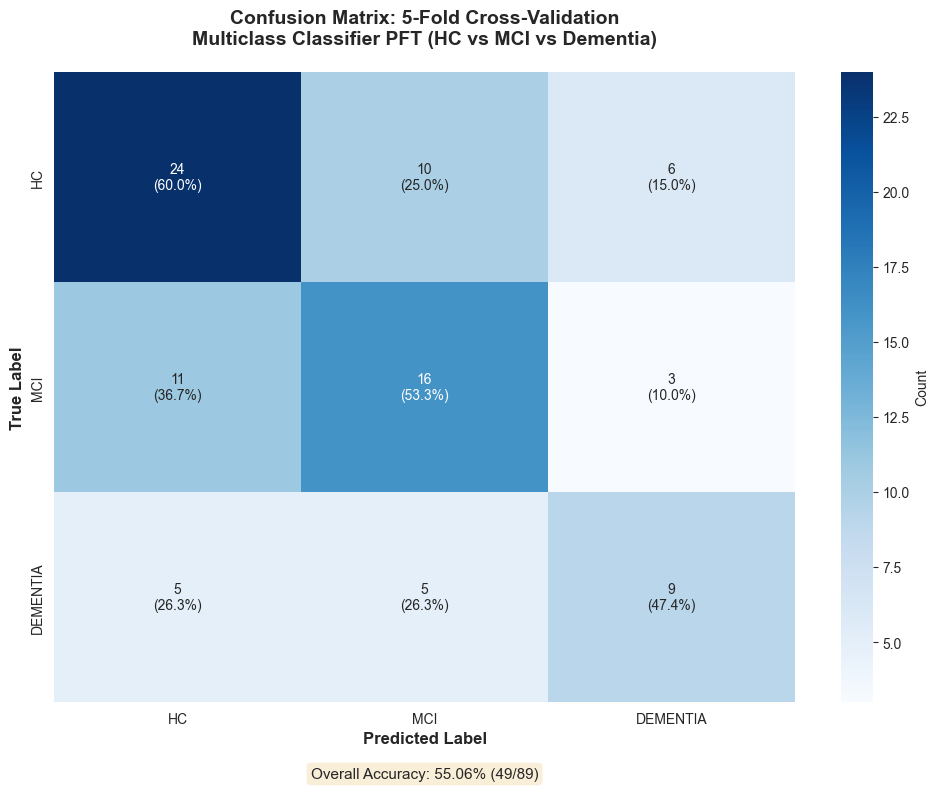

In [80]:
fig, ax = plt.subplots(figsize=(10, 8))

row_sums = cm_mc_pft.sum(axis=1)
cm_percent = np.zeros_like(cm_mc_pft, dtype=float)
for i in range(len(cm_mc_pft)):
    if row_sums[i] > 0:
        cm_percent[i, :] = cm_mc_pft[i, :].astype('float') / row_sums[i] * 100

annot_labels = []
for i in range(len(cm_mc_pft)):
    row = []
    for j in range(len(cm_mc_pft)):
        count = cm_mc_pft[i, j]
        percent = cm_percent[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

sns.heatmap(
    cm_mc_pft,
    annot=annot_labels,
    fmt='',
    cmap='Blues',
    xticklabels=class_names_mc,
    yticklabels=class_names_mc,
    cbar_kws={'label': 'Count'},
    ax=ax,
)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(
    'Confusion Matrix: 5-Fold Cross-Validation\nMulticlass Classifier PFT (HC vs MCI vs Dementia)',
    fontsize=14, fontweight='bold', pad=20,
)

total = cm_mc_pft.sum()
correct = np.trace(cm_mc_pft)
accuracy = correct / total
ax.text(0.5, -0.12, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

In [81]:
cm_df_pft = pd.DataFrame(
    cm_mc_pft,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

cm_df_pft['Total'] = cm_df_pft.sum(axis=1)

cm_percent_df_pft = pd.DataFrame(
    cm_percent,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Counts)")
print("=" * 80)
display(cm_df_pft)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Percentages - each row sums to 100%)")
print("=" * 80)
cm_percent_df_pft_formatted = cm_percent_df_pft.applymap(lambda x: f'{x:.1f}%')
display(cm_percent_df_pft_formatted)
print("=" * 80 + "\n")


CONFUSION MATRIX (Counts)


,Pred: HC,Pred: MCI,Pred: Dementia,Total
True: HC,24,10,6,40
True: MCI,11,16,3,30
True: Dementia,5,5,9,19



CONFUSION MATRIX (Percentages - each row sums to 100%)


/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89084/1326501369.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cm_percent_df_pft_formatted = cm_percent_df_pft.applymap(lambda x: f'{x:.1f}%')


,Pred: HC,Pred: MCI,Pred: Dementia
True: HC,60.0%,25.0%,15.0%
True: MCI,36.7%,53.3%,10.0%
True: Dementia,26.3%,26.3%,47.4%
